# MVP twin test: Llama 3.1 8B against the supervised models on the evaluation window

The project asks under what conditions LLM digital twins predict survey answers that depend on external state better
than supervised models do (`docs/motivation.md`). Its hypothesis is that twins predict better in a regime unlike those
the models were trained on, because a language model's general knowledge of how people respond to conditions can stand
in for training data from that regime.

A regime is the set of internal and external conditions under which people answer. The models observe only part of it,
11 respondent attributes (notebook 03) and 10 state variables (notebook 04), so each model is a function of the observed
conditions, and none can predict what a change in the unobserved ones does to answers. A supervised model's function is
fitted to the training window, which limits it in two ways. The first is coverage: observed conditions can take values
or combinations that the window lacks. The second is confounding: they can recur without the unobserved conditions that
came with them in the window, whose effects the function attributes to them. A twin's function comes from general
knowledge instead, so the hypothesis expects it to be the more accurate in both cases.

Each answer is an opinion shaped by a regime's conditions and recorded through the survey's form. A zero-shot twin
almost certainly models that form worse than supervised models (notebook 05, section 3). If this handicap is constant,
the hypothesis predicts that the twin's relative accuracy rises as the regime departs from training. The preregistration
`docs/prereg/mvp-twin.md` (OSF: https://osf.io/ahgkw) tests this prediction, with each month's state variables standing
for its regime.

The test is inconclusive: the twin's advantage does not rise with the distance in state variables, which measures a
regime only by its observed external conditions (sections 1 to 5). Sections 6 to 8 then ask the global question
directly, counting only differences beyond sampling noise. On answer shares, the calibrated twins given the state beat
every supervised model given the state on every item, and the baseline shares on three or four items of five (sections 6
and 7). On individual answers, the scaled twin given the state is level with those supervised models (ahead in 8 of 15
comparisons, behind in 5) and beats the baseline shares on every item, whereas the shifted twin is behind them on three
or four items and behind the baseline shares on three (section 8). Section 10 draws the conclusions.

Results are read from `experiments/mvp/2026-11-05-twin-prereg-scores/`, written by `python -m sdt.mvp.twin_score
twin-prereg-scores`, and from the two runs it scores: the twins in `2026-11-05-twin-prereg-eval/` and the supervised
models in `2026-10-26-supervised-macro-politics-ridge/`. Their per-interview files are not in git.

In [1]:
import json, warnings
warnings.filterwarnings('ignore', message='IProgress not found')        # quiet a library warning
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from scipy.stats import spearmanr
from sdt.mvp import twin
from sdt.mvp.clean import CLASSES, OUT_PATH, OUTCOMES
from sdt.mvp.encode import state_table
from sdt.mvp.primary import COMPARATORS, TWIN, monthly_distances, spearman
from sdt.mvp.run import EXPERIMENTS
from sdt.mvp.score import PERIODS, bootstrap, draw_counts
from sdt.mvp.windows import split
from sdt.paths import DATA, RAW_CSV
pd.set_option('display.max_columns', None); pd.set_option('display.width', None)
ITEMS = list(OUTCOMES)
DMP, LOGIT = 'demographics_macro_politics', 'mnl_demographics_macro_politics'
SCALED = f'twin_scale_{DMP}'
NAMES = {TWIN: 'shifted twin', SCALED: 'scaled twin', LOGIT: 'logit', 'baseline': 'baseline shares'}
SHORT = {'demographics': 'D', 'demographics_macro': 'D+M', 'demographics_politics': 'D+P', DMP: 'D+M+P'}
SUPERVISED_MODELS = [f'{f}_{fs}' for f in ['mnl', 'ridge', 'gb'] for fs in SHORT]
month = lambda m: pd.to_datetime(pd.Series(m).astype(str), format='%Y%m')
period = lambda m: 'Baseline' if m < PERIODS['Flip'] else 'Flip' if m < PERIODS['Tariffs'] else 'Tariffs'
label = lambda m: f"{m.split('_', 1)[0]} {SHORT[m.split('_', 1)[1]]}"      # 'mnl_demographics' -> 'mnl D'
EVENTS = ['2024-11-01', '2025-02-01']          # first survey months of Flip and Tariffs, dashed in the figures

clean = pd.read_parquet(OUT_PATH)
train, test = split(clean)
key = clean.set_index('CASEID')
SCORES, TWINS = EXPERIMENTS / '2026-11-05-twin-prereg-scores', EXPERIMENTS / '2026-11-05-twin-prereg-eval'
SUPERVISED = EXPERIMENTS / '2026-10-26-supervised-macro-politics-ridge'
scores = pd.read_csv(SCORES / 'scores.csv')
cell = scores.set_index(['period', 'group', 'model', 'item']).sort_index()
allc = cell.loc[('all', 'all')]                # every model and item over all months and respondents
primary = json.load(open(SCORES / 'primary.json'))
months = pd.read_csv(SCORES / 'primary_months.csv').set_index('month')
W = pd.read_csv(SCORES / 'primary_distances.csv').pivot(index='month', columns=['model', 'item'], values='wasserstein')
by_period = pd.read_csv(SCORES / 'calibration_by_period.csv')
meta, twin_meta = json.load(open(SCORES / 'run.json')), json.load(open(TWINS / 'run.json'))
print(f"Scoring run of {meta['date']} at commit {meta['commit'][:7]}; twin run at commit {twin_meta['commit'][:7]}; "
      f"supervised run at commit {meta['sources']['supervised']['commit'][:7]}")

# Evaluation predictions of the two calibrated twins on D and D+M+P, the shifted twin on D+P, the 12 supervised models
# and the baseline shares
TWIN_MODELS = [TWIN, SCALED, 'twin_shift_demographics', 'twin_scale_demographics',
               'twin_shift_demographics_politics']
pred = pd.concat([pd.read_parquet(TWINS / 'predictions.parquet', filters=[('model', 'in', TWIN_MODELS)]),
                  pd.read_parquet(SUPERVISED / 'predictions.parquet',
                                  filters=[('model', 'in', SUPERVISED_MODELS + ['baseline'])])])
pred = pred[pred.CASEID.isin(test.CASEID)].reset_index(drop=True)
answer = key.loc[pred.CASEID, ITEMS].to_numpy()[np.arange(len(pred)), pred.item.map(ITEMS.index).to_numpy()]
pred = pred.assign(**{c: key.loc[pred.CASEID, c].to_numpy() for c in ['YYYYMM', 'WT']},
                   party=key.loc[pred.CASEID, 'POLAFF'].astype(object).fillna('none').to_numpy(),
                   actual_fav=answer == 'fav', actual_unf=answer == 'unf')

def net_balance(item, models, party=None):
    """Weighted net balance, % favourable − % unfavourable, by evaluation month: actual, and predicted by each model."""
    p = pred[pred.item == item]
    if party is not None:
        p = p[p.party == party]
    nb = lambda g, f, u: 100 * np.average(g[f].astype(float) - g[u].astype(float), weights=g.WT)
    by_month = lambda m, f, u: p[p.model == m].groupby('YYYYMM').apply(nb, f, u, include_groups=False)
    return pd.DataFrame({'actual': by_month('baseline', 'actual_fav', 'actual_unf')}
                        | {m: by_month(m, 'fav', 'unf') for m in models})

def mark(model, item, score='wasserstein', group='all', period='all', fmt='+.3f'):
    """A score or difference in one cell of period and group, with * when its 95% interval excludes zero."""
    r = cell.loc[(period, group, model, item)]
    return f"{r[score]:{fmt}}{'*' if r[f'{score}_lo'] > 0 or r[f'{score}_hi'] < 0 else ''}"

Scoring run of 2026-11-05 at commit 0f6b6bc; twin run at commit e4b385b; supervised run at commit 53877d8


## 1. The plan

The plan states the hypothesis as: an LLM twin's accuracy in predicting survey answers, relative to supervised models
given the same inputs, increases as the inputs become less like those of the training data. Its primary test turns each
part of that sentence into a quantity: the inputs and the models (section 1.1), "less like" (section 1.2), relative
accuracy (section 1.3), and the statistic, interval and decision rule that test "increases" (section 1.4).

The plan was registered on 3 November 2026, when every evaluation answer and supervised score was known and no twin
prediction for an evaluation interview existed. Its outcome rests on the primary test alone (section 3). Every other
analysis is secondary (listed in the plan and reported in full: the three periods, the other twins and supervised
models, the individual score, items, parties and the two diagnostics of section 5) or exploratory (not listed in the
plan: for example the trade-policy index of section 4 and the split of individual skill in section 8). Section 9 lists
the exploratory analyses and says which were chosen with the results known.

### 1.1 Inputs and models

The primary test uses the full feature set (labelled D+M+P): the 11 respondent attributes (D), the 8 macro state
variables (M) and the 2 political state variables (P). It compares the shifted twin on D+M+P with the multinomial logit
on D+M+P and with the baseline shares, which use no inputs.

The shifted twin adds a constant b to each answer's log-odds in the zero-shot twin, the language model's own
probabilities. b is fitted to the training window's 2,257 web interviews (notebook 05, section 3.1). The plan makes this
twin primary for two reasons. Its answer shares match those of the training web interviews, as the logit's and the
baseline shares' do, so the three models start level and each misses a later month's shares only by its error in how
they moved since then. And a constant changes no difference in log-odds between two predictions, so how the twin's
predictions differ, between respondents and between months, stays the language model's own.

The plan keeps the two other twins out of the primary test. The zero-shot twin starts far from the answer shares (6%
unfavourable on `BUS5` against an actual 26%; notebook 05, section 5.1), and near 6% a given move in log-odds changes
the share less than near 26%, so its gap can widen as answers move even when it moves the right way. The scaled twin
also multiplies the log-odds by a factor a, fitted to the training web interviews, which rescales every such difference
by an amount fitted within one regime.

### 1.2 Dissimilarity

The hypothesis speaks of inputs that become "less like" those of the training data. The plan measures this for each
evaluation month by a dissimilarity d_t, the distance from the month's 10 state variables to those of the nearest of the
90 training months. Each variable is first standardised by its mean and standard deviation over the training months, so
that variables in different units share one scale. Only the state variables enter, so the test registers a new regime
only through its observed external conditions.

The party variables dominate d_t. Each is 0 or 1 with a standard deviation of 0.5, so a change of party is a gap of 2.
In December 2024, whose nearest training month is July 2024, the election winner's party contributes 4.00 of the 4.76
summed squared gaps. d_t therefore falls into three groups (Figure 1): at most 0.73 until November 2024; 2.18 in
December and January, the only evaluation months in which the election winner and the sitting president differ; and 1.20
to 1.57 from February 2025.

In [2]:
# Claim checks for section 1.2: d_t recomputed here reproduces the scoring run's; in December 2024, whose nearest training
# month is July 2024, the election winner's party contributes 4.00 of the 4.76 summed squared gaps; and d_t falls into
# three groups
S = state_table(tuple(sorted(clean.YYYYMM.unique())))
tr = S.loc[sorted(train.YYYYMM.unique())]
Z = (S - tr.mean()) / tr.std(ddof=0)
gaps = lambda t: np.sqrt(((Z.loc[tr.index] - Z.loc[t]) ** 2).sum(axis=1))      # distance to every training month
assert len(tr) == 90 and np.allclose([gaps(t).min() for t in months.index], months.d, atol=1e-5)
squared = (Z.loc[202412] - Z.loc[gaps(202412).idxmin()]) ** 2
assert gaps(202412).idxmin() == 202407 and round(squared.winner_R, 2) == 4.00 and round(squared.sum(), 2) == 4.76
assert round(months.d.loc[:202411].max(), 2) == 0.73 and (months.d.loc[202412:202501].round(2) == 2.18).all()
assert (round(months.d.loc[202502:].min(), 2), round(months.d.loc[202502:].max(), 2)) == (1.20, 1.57)

### 1.3 Advantage

The hypothesis speaks of the twin's accuracy relative to another model's. The plan measures this for each evaluation
month by an advantage A_t, the comparator's distance from the actual answer shares minus the shifted twin's, averaged
over the five items. The distance is the Wasserstein distance between predicted and actual weighted answer shares
(notebook 03, section 2.2), so a positive A_t means that the twin is closer.

### 1.4 Statistic, interval and decision rule

The hypothesis says that this relative accuracy increases as the inputs become less like the training data, so the test
asks whether A_t rises with d_t. The statistic is Spearman's rank correlation ρ between d_t and A_t across the 19
months, against each comparator: 1 if A_t rises in exactly the order of d_t, and −1 if it falls in that order. Its 95%
interval comes from a bootstrap of 1,000 draws (seed 0). Each draw redraws every month's interviews with replacement, as
many as the month had, and recomputes every monthly distance, A_t and ρ. Notice that all models and all items use the
same draw, where each draw stands in for another sample of respondents. If we were to draw separately for the two
models, A_t would compare them on different respondents, and its spread across draws would include the difference
between two samples, which the real A_t never contains. If we were to draw separately for the five items, A_t would
average five items from different respondents, and its spread across draws would miss the correlation between one
respondent's five answers. Either way the interval would not be the interval of the ρ that was computed. Every interval
on the evaluation window in this notebook uses these draws. The months are held fixed, so an interval covers which
households were interviewed, not which months occurred.

The plan fixed the outcome: support if ρ's interval lies above 0 against both comparators, contradiction if it lies
below 0 against either, and inconclusive otherwise. This notebook corrects that rule, because it tests more than the
hypothesis requires. The two comparators test different claims. Against the logit, ρ tests the hypothesis as stated: the
twin's accuracy relative to a supervised model given the same inputs. The baseline shares use no inputs and predict the
training shares in every month, so the twin's lead over them is what the twin gains by predicting a change at all.
Against them, ρ tests whether that gain grows with d_t. The hypothesis requires the lead over the logit to grow, not
that gain. Under the plan's rule, a fall in that gain would count as a contradiction even if the lead over the logit
rose. The corrected rule applies the plan's thresholds to ρ against the logit alone, and section 3 reports ρ against the
baseline shares beside it. The correction was made with the results known. Nonetheless, both rules give the same outcome
(section 3).

## 2. The run

The twin run used the pilot's command (notebook 05, section 4) at the commit of the preregistration tag, with the
evaluation interviews added: Llama 3.1 8B Instruct in fp32 at batch size 16, one feature set on each of four NVIDIA RTX
PRO 6000 GPUs, in about 3.5 hours (its `run.json` records GPU time summed over the four). Its probabilities for the
training web interviews reproduce the pilot's:

In [3]:
pilot = pd.read_parquet(EXPERIMENTS / '2026-10-30-twin-pilot-training-web' / 'option_probs.parquet')
raw = pd.read_parquet(TWINS / 'option_probs.parquet')
both = pilot[pilot.stage == 'base'].merge(raw[raw.interviews == 'train-web'], on=['feature_set', 'item', 'CASEID'],
                                          suffixes=('_pilot', '_eval'))
same = all(np.array_equal(both[f'{c}_pilot'], both[f'{c}_eval'], equal_nan=True) for c in twin.RAW)
print(f"{twin_meta['per_stage']['base']['prompts']:,} prompts: {twin_meta['interviews']['eval']:,} evaluation and "
      f"{twin_meta['interviews']['train-web']:,} training web interviews x 5 items x 4 feature sets")
print(f"{len(both):,} training web probabilities identical to the pilot's: {same}")

468,800 prompts: 21,183 evaluation and 2,257 training web interviews x 5 items x 4 feature sets
45,140 training web probabilities identical to the pilot's: True


`sdt.mvp.twin_score` wrote its scores only after four checks passed: `data.csv` and the raw twin probabilities have the
SHA-256 that the runs recorded, and the calibration and the supervised scores, recomputed, match the saved ones.

## 3. Outcome

ρ against each comparator, with its interval and its range when any one month is left out:

In [4]:
rho = pd.DataFrame({NAMES[c]: {**primary['rho'][c],
                               'lowest, one month left out': months[f'rho_without_month_{c}'].min(),
                               'highest, one month left out': months[f'rho_without_month_{c}'].max()}
                    for c in COMPARATORS}).T
lo, hi = (primary['rho'][LOGIT][k] for k in ['lo', 'hi'])
corrected = 'support' if lo > 0 else 'contradiction' if hi < 0 else 'inconclusive'      # the rule of section 1.4
print(f"Outcome by the plan's rule: {primary['outcome']}; by the corrected rule: {corrected}")
rho.rename(columns={'observed': 'rho', 'lo': '2.5%', 'hi': '97.5%'}).round(2)

Outcome by the plan's rule: inconclusive; by the corrected rule: inconclusive


,rho,2.5%,97.5%,"lowest, one month left out","highest, one month left out"
logit,-0.01,-0.10,0.10,-0.11,0.16
baseline shares,0.05,-0.12,0.42,-0.10,0.13


The outcome is inconclusive under both rules. By the corrected rule, ρ against the logit is −0.01 with an interval from
−0.10 to 0.10, which includes zero and rules out all but a weak association in either direction. Leaving out any one
month keeps it between −0.11 and 0.16. The plan's rule also needs the interval against the baseline shares to lie above
zero, and it runs from −0.12 to 0.42. This interval is wider because A_t against the baseline shares varies little from
month to month (Figure 1), so sampling noise easily reorders the months by A_t, which changes ρ.

## 4. Why the months came out this way

Section 3 ends the confirmatory test. This section explains its result, reading A_t against the logit as the corrected
rule does. Figure 1 adds an index of trade-policy uncertainty, one condition that the models do not observe: the
trade-policy component of Baker, Bloom and Davis's economic policy uncertainty index, built from newspaper articles.

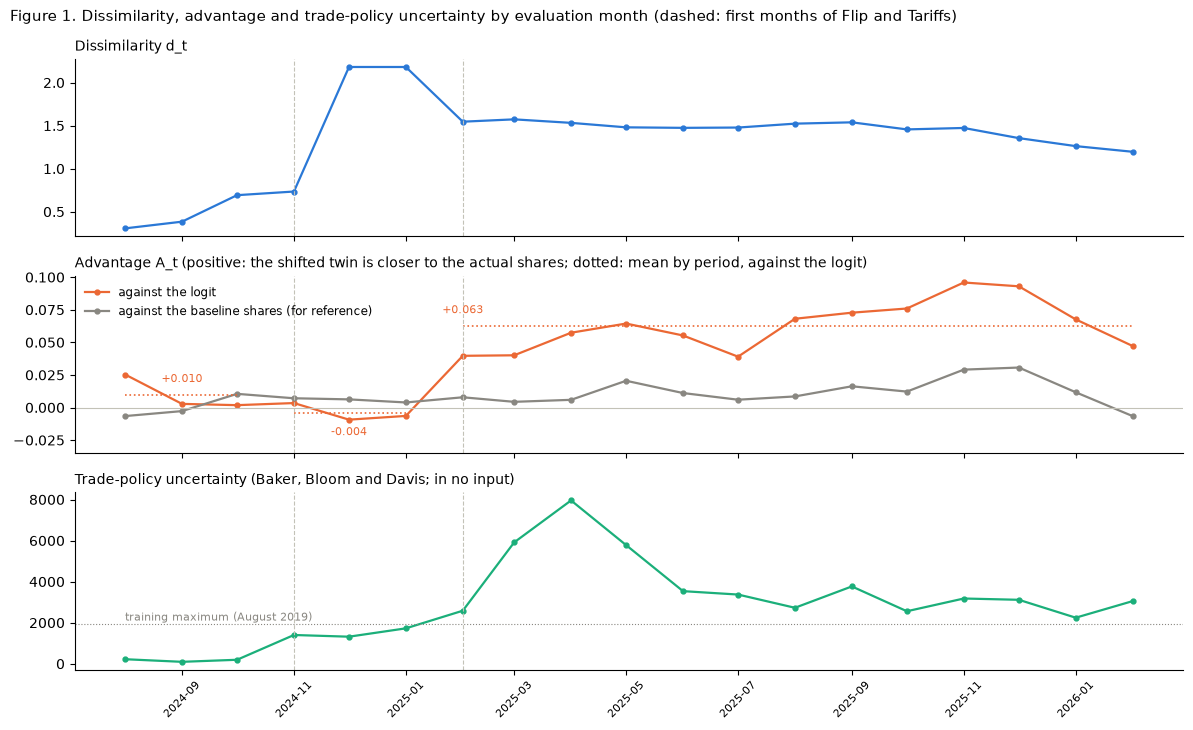

In [5]:
epu = pd.read_csv(DATA / 'external' / 'fred' / 'EPUTRADE.csv', parse_dates=['observation_date'])
epu = pd.Series(epu.EPUTRADE.to_numpy(), index=epu.observation_date.dt.year * 100 + epu.observation_date.dt.month)
epu_train = epu.loc[sorted(train.YYYYMM.unique())]
by = lambda s: s.groupby(s.index.map(period)).mean().loc[list(PERIODS)]          # mean by period
A = months[f'A_{LOGIT}']
# Claim checks: against the logit, A_t is below zero only in December and January, the two months of highest d_t; its 13
# highest values are the 13 tariff months; and it averages 0.010, -0.004 and 0.063 by period
assert set(A.index[A < 0]) == {202412, 202501} == set(months.d.nlargest(2).index)
assert A.loc[PERIODS['Tariffs']:].min() > A.loc[:202501].max() and len(A.loc[PERIODS['Tariffs']:]) == 13
assert np.allclose(by(A), [0.010, -0.004, 0.063], atol=5e-4)

x = month(months.index)
fig, axes = plt.subplots(3, 1, figsize=(12, 7.4), sharex=True)
axes[0].plot(x, months.d.values, color='#2a78d6', lw=1.6, marker='o', ms=3.5)
for c, color, note in zip(COMPARATORS, ['#eb6834', '#898781'], ['', ' (for reference)']):
    axes[1].plot(x, months[f'A_{c}'].values, color=color, lw=1.6, marker='o', ms=3.5, label=f'against the {NAMES[c]}{note}')
for p, mean in by(A).items():                    # dotted: each period's mean A_t against the logit
    xs = x[np.asarray(months.index.map(period) == p)]
    axes[1].hlines(mean, xs.iloc[0], xs.iloc[-1], color='#eb6834', lw=1.2, ls=':')
    axes[1].annotate(f'{mean:+.3f}', (xs.iloc[0 if len(xs) > 3 else 1], mean), xytext=(0, -16 if mean < 0 else 9),
                     textcoords='offset points', ha='center', fontsize=8, color='#eb6834')
axes[1].set_ylim(bottom=-0.035)
axes[1].axhline(0, color='#c3c2b7', lw=0.8); axes[1].legend(frameon=False, fontsize=8.5, loc='upper left')
axes[2].plot(x, epu.loc[months.index].values, color='#1baf7a', lw=1.6, marker='o', ms=3.5)
axes[2].axhline(epu_train.max(), color='#898781', lw=0.8, ls=':')
axes[2].text(x.iloc[0], epu_train.max() * 1.08, f'training maximum ({month([epu_train.idxmax()]).iloc[0]:%B %Y})',
             fontsize=8, color='#898781')
for ax, title in zip(axes, ['Dissimilarity d_t',
                            'Advantage A_t (positive: the shifted twin is closer to the actual shares; '
                            'dotted: mean by period, against the logit)',
                            'Trade-policy uncertainty (Baker, Bloom and Davis; in no input)']):
    for d in EVENTS:
        ax.axvline(pd.Timestamp(d), color='#c3c2b7', lw=0.8, ls='--')
    ax.set_title(title, loc='left', fontsize=10); ax.spines[['top', 'right']].set_visible(False)
axes[2].tick_params(axis='x', labelsize=8, rotation=45)
fig.suptitle('Figure 1. Dissimilarity, advantage and trade-policy uncertainty by evaluation month '
             '(dashed: first months of Flip and Tariffs)', x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

Against the logit, A_t does not follow the order of d_t. December and January, where d_t is highest, have the lowest A_t
and the only two values below zero (section 4.1). The 13 tariff months, where d_t is middling, have the 13 highest
(section 4.2). Section 4.3 turns to what d_t measured.

### 4.1 December and January

Figure 2 shows the net balance, the favourable share minus the unfavourable share, of three items, actual and predicted:

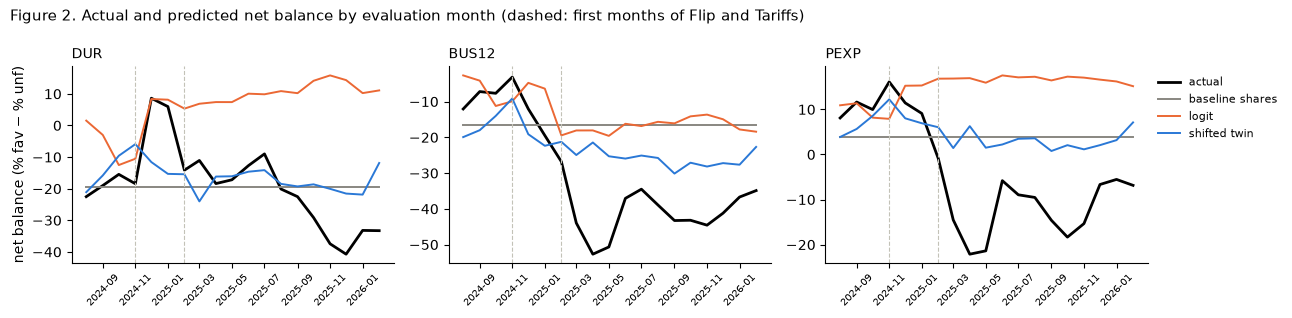

In [6]:
shown = {item: net_balance(item, ['baseline', LOGIT, TWIN]) for item in ['DUR', 'BUS12', 'PEXP']}
draws = draw_counts(test, 1000, 0)               # the scoring run's draws (N_BOOT and SEED in sdt.mvp.twin_score)
_, drawn = monthly_distances(pred, test, draws, [TWIN, *COMPARATORS])

def rho_with(order, comparator=LOGIT, items=ITEMS):
    """Spearman correlation across the 19 months of `order` with A_t over `items`, and its 95% interval on `draws`."""
    A = (W[comparator][items] - W[TWIN][items]).mean(axis=1).to_numpy()
    on_draws = spearman(np.asarray(order, float), np.mean([drawn[i, comparator] - drawn[i, TWIN] for i in items], axis=0))
    return np.array([spearman(np.asarray(order, float), A), *np.percentile(on_draws, [2.5, 97.5])])

# Claim checks for the text below. `rho_with` reproduces the scoring run's rho and intervals. On DUR, the actual net
# balance, the logit's and the twin's from November to December, and the logit's against the actual one from February
# 2025. Among DUR respondents, the share who call it a good time to buy because prices are going up (reason code 13 in
# data/DDI XML.txt) or taxes are changing (code 19), in either of two mentions. Without DUR, A_t against the logit is
# above zero in December and January, and rho's interval lies above zero; without any other item, it includes zero.
assert np.allclose([rho_with(months.d, c) for c in COMPARATORS],
                   [[primary['rho'][c][k] for k in ['observed', 'lo', 'hi']] for c in COMPARATORS], atol=1e-6)
dur = shown['DUR']
assert dur.loc[[202411, 202412]].round().astype(int)[['actual', LOGIT, TWIN]].to_numpy().tolist() == [[-18, -11, -6], [9, 8, -12]]
assert dur.loc[PERIODS['Tariffs']:, LOGIT].between(5, 16).all() and round(dur.actual.min()) == -41
reasons = pd.read_csv(RAW_CSV, skipinitialspace=True, usecols=['CASEID', 'DURRN1', 'DURRN2'])
asked = clean[clean.DUR.notna()].merge(reasons, on='CASEID')
buying = asked.WT.where(asked[['DURRN1', 'DURRN2']].isin([13, 19]).any(axis=1), 0).groupby(asked.YYYYMM).sum() \
    / asked.WT.groupby(asked.YYYYMM).sum()
assert (100 * buying[[202411, 202412, 202501]]).round().tolist() == [10, 24, 26] and buying.loc[:202411].max() < buying[202412]
rest = ITEMS[:4]                                                       # every item but DUR
lead = (W[LOGIT][rest] - W[TWIN][rest]).mean(axis=1)
assert (lead[[202412, 202501]] > 0).all()
assert np.allclose(rho_with(months.d, items=rest), [0.28, 0.09, 0.34], atol=0.005)
assert all(lo < 0 < hi for _, lo, hi in (rho_with(months.d, items=[i for i in ITEMS if i != out]) for out in rest))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (item, nb) in zip(axes, shown.items()):
    ax.plot(month(nb.index), nb.actual.values, color='black', lw=2, label='actual')
    for m, color in [('baseline', '#898781'), (LOGIT, '#eb6834'), (TWIN, '#2a78d6')]:
        ax.plot(month(nb.index), nb[m].values, color=color, lw=1.4, label=NAMES[m])
    for d in EVENTS:
        ax.axvline(pd.Timestamp(d), color='#c3c2b7', lw=0.8, ls='--')
    ax.set_title(item, loc='left', fontsize=10); ax.tick_params(axis='x', labelsize=7, rotation=45)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('net balance (% fav − % unf)')
axes[-1].legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
fig.suptitle('Figure 2. Actual and predicted net balance by evaluation month (dashed: first months of Flip and Tariffs)',
             x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

A_t fell below zero in these months through one item, `DUR`. Its actual net balance jumped from −18 in November to +9 in
December. The logit's prediction jumped with it, from −11 to +8, because `winner_R` turned to 1 and its coefficient
carries the high `DUR` answers of the first Trump presidency (notebook 04, section 5.3). The twin's prediction fell from
−6 to −12. The logit then stayed between +5 and +16 while answers fell to −41, so its match in December and January came
from the confound.

Respondents were most likely buying ahead of tariffs, an unobserved condition: the share of `DUR` respondents who called
it a good time to buy because prices are going up or taxes are changing rose from 10% in November to 24% in December and
26% in January, above every earlier month in the data.

Without `DUR`, ρ against the logit is 0.28 with an interval from 0.09 to 0.34, and leaving out any other item keeps zero
inside the interval. The inconclusive outcome thus depends on `DUR`. But `DUR` was singled out after the results were
known, so ρ without it is not support for the hypothesis.

December and January have the highest d_t because the election winner's party had changed and the president's had not
(section 1.2). Figure 3 shows how each model responded, in the net balance of `PEXP`, whether the family will be better
off a year from now, by party:

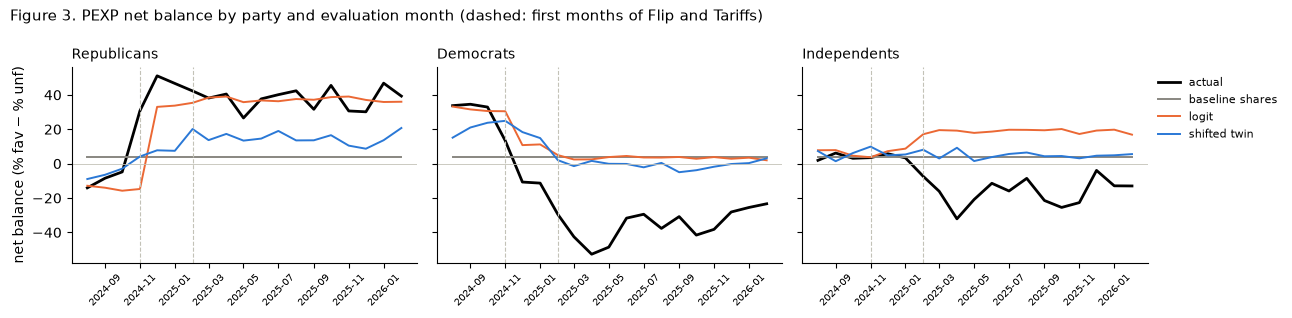

Republican minus Democratic net balance, mean over the tariff months: actual 73, logit 34, shifted twin 16


In [7]:
party = {p: net_balance('PEXP', ['baseline', LOGIT, TWIN], p) for p in ['Rep', 'Dem', 'Ind']}
ahead = party['Rep'] > party['Dem']              # months in which Republicans are above Democrats
# Claim checks: Republicans are above Democrats from November 2024 in the answers, from December in the logit's
# predictions and from February 2025 in the twin's
assert [ahead.index[ahead[m]].min() for m in ['actual', LOGIT, TWIN]] == [202411, 202412, 202502]
assert all(ahead.loc[ahead.index[ahead[m]].min():, m].all() for m in ['actual', LOGIT, TWIN])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, (p, nb) in zip(axes, party.items()):
    ax.plot(month(nb.index), nb.actual.values, color='black', lw=2, label='actual')
    for m, color in [('baseline', '#898781'), (LOGIT, '#eb6834'), (TWIN, '#2a78d6')]:
        ax.plot(month(nb.index), nb[m].values, color=color, lw=1.4, label=NAMES[m])
    for d in EVENTS:
        ax.axvline(pd.Timestamp(d), color='#c3c2b7', lw=0.8, ls='--')
    ax.axhline(0, color='#c3c2b7', lw=0.6)
    ax.set_title({'Rep': 'Republicans', 'Dem': 'Democrats', 'Ind': 'Independents'}[p], loc='left', fontsize=10)
    ax.tick_params(axis='x', labelsize=7, rotation=45); ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('net balance (% fav − % unf)')
axes[-1].legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
fig.suptitle('Figure 3. PEXP net balance by party and evaluation month (dashed: first months of Flip and Tariffs)',
             x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()
gap = (party['Rep'] - party['Dem']).loc[PERIODS['Tariffs']:].mean()
print('Republican minus Democratic net balance, mean over the tariff months: ' +
      ', '.join(f'{NAMES.get(m, m)} {gap[m]:.0f}' for m in ['actual', LOGIT, TWIN]))

Respondents reversed at the election, inside the November window, and the logit in December, when `winner_R` turned to
1. The shifted twin kept Democrats above Republicans until the president changed in February 2025: it responds to the
sitting president rather than the election winner. Over the tariff months it then separated the parties by 16 points,
against 73 for respondents and 34 for the logit. In the answer shares of all respondents the two parties' errors largely
cancel, so A_t does not show this lag.

### 4.2 The tariff months

From February 2025, answers collapsed: the net balance of `BUS12` fell from −27 in February to −53 in April (Figure 2).
The economic variables stayed inside their training ranges (notebook 04, section 1), and the party variables say only
that a Republican governs, so the change lay mostly in unobserved conditions.

The logit moved the wrong way: with a Republican president it predicted the optimism of the first Trump presidency, a
`PEXP` net balance of +15 to +18 against an actual −22 to −1 (section 7.3 explains why). The shifted twin moved the
right way but too little: on every item except `PAGO`, its net balance moved a quarter to a half as far as the actual
one (the ratio of their standard deviations over the 19 months is 0.25 to 0.46).

A_t against the logit is highest in these months: 0.063 on average, against 0.010 in Baseline and −0.004 in Flip (dotted
in Figure 1). Of the 0.063, 0.051 is how much farther the logit is from the actual shares than the baseline shares,
which never move, and 0.012 is how much closer the twin is.

### 4.3 What d_t measured

d_t measures how far a month departs from training only in its observed external conditions, and two of its properties
make it a poor measure of how far a regime departs.

**It counted changes of party far above changes in the economy,** so it fell into three groups (section 1.2), and the
months make up closer to three episodes than to 19.

**It cannot see unobserved conditions, which moved answers most.** How far answers moved from the training shares,
measured by the baseline shares' monthly distance, correlates 0.31 with d_t and 0.82 with trade-policy uncertainty. That
index exceeded its training maximum in every tariff month (Figure 1), but d_t placed the tariff months nearest to July
2019 to March 2020, in the earlier trade war, because the observed states were alike.

The test thus asked whether the twin gains where the observed state is least familiar, and here it does not. It could
not ask whether the twin gains where the regime is least familiar, because the change of 2025 lay mostly in unobserved
conditions.

In [8]:
# Claim checks for sections 4.2 and 4.3. The net balance of BUS12 in February and April 2025, and of PEXP in the tariff
# months, actual and the logit's. Over the 19 months, the correlation of each model's net balance with the actual one
# and, for the twin, the ratio of their standard deviations. In the tariff months, A_t against the baseline shares. How
# far answers moved against d_t and against trade-policy uncertainty, which is above its training maximum in every
# tariff month, and the nearest training month of every tariff month.
tariffs = months.index[months.index >= PERIODS['Tariffs']]
nb = {item: net_balance(item, [LOGIT, TWIN]) for item in ITEMS}
assert nb['BUS12'].actual[[202502, 202504]].round().tolist() == [-27, -53]
assert nb['PEXP'].loc[tariffs, LOGIT].between(15, 18).all() and nb['PEXP'].loc[tariffs, 'actual'].between(-22.5, -0.5).all()
r = pd.DataFrame({m: {item: nb[item][m].corr(nb[item].actual) for item in ITEMS} for m in [LOGIT, TWIN]})
k = pd.Series({item: nb[item][TWIN].std() / nb[item].actual.std() for item in ITEMS})
assert list(r.index[r[LOGIT] < 0]) == ['PEXP', 'BUS5', 'DUR'] and [r[TWIN].min().round(2), r[TWIN].max().round(2)] == [0.39, 0.82]
assert [k.drop('PAGO').min().round(2), k.drop('PAGO').max().round(2)] == [0.25, 0.46] and k.PAGO > 0.75
assert np.isclose(by(months['A_baseline'])['Tariffs'], 0.012, atol=5e-4)
moved = W['baseline'].mean(axis=1)
assert [round(spearmanr(o, moved)[0], 2) for o in [months.d, epu.loc[months.index]]] == [0.31, 0.82]
assert epu.loc[tariffs].min() > epu_train.max()
assert all(201907 <= gaps(t).idxmin() <= 202003 for t in tariffs)

## 5. Diagnostics

### 5.1 Other orderings of the months

The plan's first diagnostic is the Spearman correlation of d_t with elapsed months. Its time sibling replaces d_t with
elapsed months in the statistic, with the same draws. The last rows replace it with trade-policy uncertainty, an
ordering chosen with the results known:

In [9]:
print(f"Spearman correlation of d_t with elapsed months: {primary['spearman_d_elapsed_months']:.2f}")
orderings = {'d_t': months.d, 'elapsed months': months.elapsed_months, 'trade-policy uncertainty': epu.loc[months.index]}
table = pd.DataFrame({(o, NAMES[c]): rho_with(x, c) for o, x in orderings.items() for c in COMPARATORS},
                     index=['rho', '2.5%', '97.5%']).T
assert np.allclose(table.loc['elapsed months'], [[primary['rho_time'][c][k] for k in ['observed', 'lo', 'hi']]
                                                 for c in COMPARATORS], atol=1e-6)
assert epu.loc[tariffs].min() > epu.loc[months.index[0]:202501].max()      # every tariff month above the six before
table.round(2)

Spearman correlation of d_t with elapsed months: 0.06


rho  2.5%  97.5%
d_t                      logit           -0.01 -0.10   0.10
                         baseline shares  0.05 -0.12   0.42
elapsed months           logit            0.80  0.74   0.85
                         baseline shares  0.49  0.19   0.65
trade-policy uncertainty logit            0.58  0.50   0.63
                         baseline shares  0.29  0.08   0.59

d_t and elapsed months are nearly uncorrelated (0.06), so the two statistics order the months almost independently.
Against the logit, A_t rises with elapsed months: ρ is 0.80 with an interval from 0.74 to 0.85. Elapsed time orders the
tariffs with every other change of 2025, so it says when the twin gained, and section 4.2 says why. A_t also rises with
trade-policy uncertainty: ρ is 0.58 with an interval from 0.50 to 0.63. But the index places every tariff month above
the six months before, as elapsed time does, so it does not separate the tariffs from the other changes of 2025 either.
No decision rule applies to these two orderings.

### 5.2 Calibration across periods

The plan's second diagnostic refits both calibrations on each period's interviews, from the zero-shot twin's
probabilities on D+M+P, to show how far the training fit lies from each period's best fit. The training fit's 95% range
comes from 200 redraws of its 2,200 interviews within months.

In [10]:
z = pd.read_parquet(TWINS / 'predictions.parquet', filters=[('model', '==', f'twin_{DMP}')])
z = z[z.CASEID.isin(train[train.web == 1].CASEID)].join(key[['YYYYMM', 'WT'] + ITEMS], on='CASEID')
rng, redrawn = np.random.default_rng(0), []
for item, g in z.groupby('item'):
    g = g.reset_index(drop=True)
    within = [np.flatnonzero(g.YYYYMM.to_numpy() == m) for m in g.YYYYMM.unique()]
    for _ in range(200):
        r = g.iloc[np.concatenate([rng.choice(ix, len(ix)) for ix in within])]
        for name, scale in [('shift', False), ('scale', True)]:
            fit = twin.fit_calibration(r[CLASSES], r[item].astype(str), r.WT, scale)
            redrawn.append({'item': item, 'calibration': name, 'a': fit['a'], 'b_fav': fit['fav'], 'b_unf': fit['unf']})
redrawn = pd.DataFrame(redrawn)
p = by_period[by_period.feature_set == DMP]
out = {}
for param, name, row in [('a', 'scale', 'a (scaled twin)'), ('b_fav', 'shift', 'b_fav (shifted twin)'),
                           ('b_unf', 'shift', 'b_unf (shifted twin)')]:
    fit = p[p.calibration == name].pivot(index='item', columns='fitted_on', values=param)
    for item in ITEMS:
        lo, hi = np.percentile(redrawn[(redrawn.calibration == name) & (redrawn.item == item)][param], [2.5, 97.5])
        out[(row, item)] = {'training web': f"{fit.loc[item, 'training web']:.2f}",
                            'its 95% range': f'[{lo:.2f}, {hi:.2f}]', **{q: f'{fit.loc[item, q]:.2f}' for q in PERIODS}}
pd.DataFrame(out).T

training web  its 95% range Baseline  Flip Tariffs
a (scaled twin)      PAGO          0.46   [0.37, 0.53]     0.39  0.38    0.35
                     PEXP          0.30   [0.21, 0.41]     0.34  0.11    0.21
                     BUS12         0.61   [0.47, 0.76]     0.67  0.07    0.34
                     BUS5          0.31   [0.22, 0.42]     0.35  0.00    0.47
                     DUR           0.95   [0.62, 1.32]     1.04  0.70    0.52
b_fav (shifted twin) PAGO          0.69   [0.54, 0.82]     0.69  0.53    0.49
                     PEXP          1.23   [1.09, 1.36]     1.30  1.51    1.36
                     BUS12         0.59   [0.48, 0.73]     0.74  0.80    1.14
                     BUS5          1.20   [1.06, 1.33]     1.46  1.63    1.91
                     DUR          -0.39  [-0.81, 0.17]    -0.08  0.20    0.03
b_unf (shifted twin) PAGO          1.55   [1.41, 1.70]     1.53  1.19    1.28
                     PEXP          1.00   [0.89, 1.16]     0.88  1.18    1.76
                     BUS12         0.93   [0.82, 1.07]     0.70  0.89    1.78
                     BUS5          2.06   [1.91, 2.20]     1.90  2.28    2.98
                     DUR           0.38  [-0.05, 0.94]     0.76  0.75    0.90

Two changes lie well outside that range. In Flip, the scale a falls to 0.00 to 0.11 on `PEXP`, `BUS12` and `BUS5`, so
the best fit nearly ignores the twin's differences between respondents, as its reversed partisan ordering implies. In
Tariffs, b_unf rises by 0.8 to 0.9 on the same items, because respondents chose the unfavourable answer more often than
the twin predicted. Because a refitted constant also absorbs the twin's errors about opinions, neither change shows
whether the survey's form changed.

## 6. All models

Sections 6 to 8 ask the global question directly: over the 19 evaluation months, which model predicts best? Figure 4
extends notebook 04's Figure 2 with the 12 twins, named by calibration (`twin` for the zero-shot twin, `twin_shift` for
the shifted twin and `twin_scale` for the scaled twin) and by feature set:

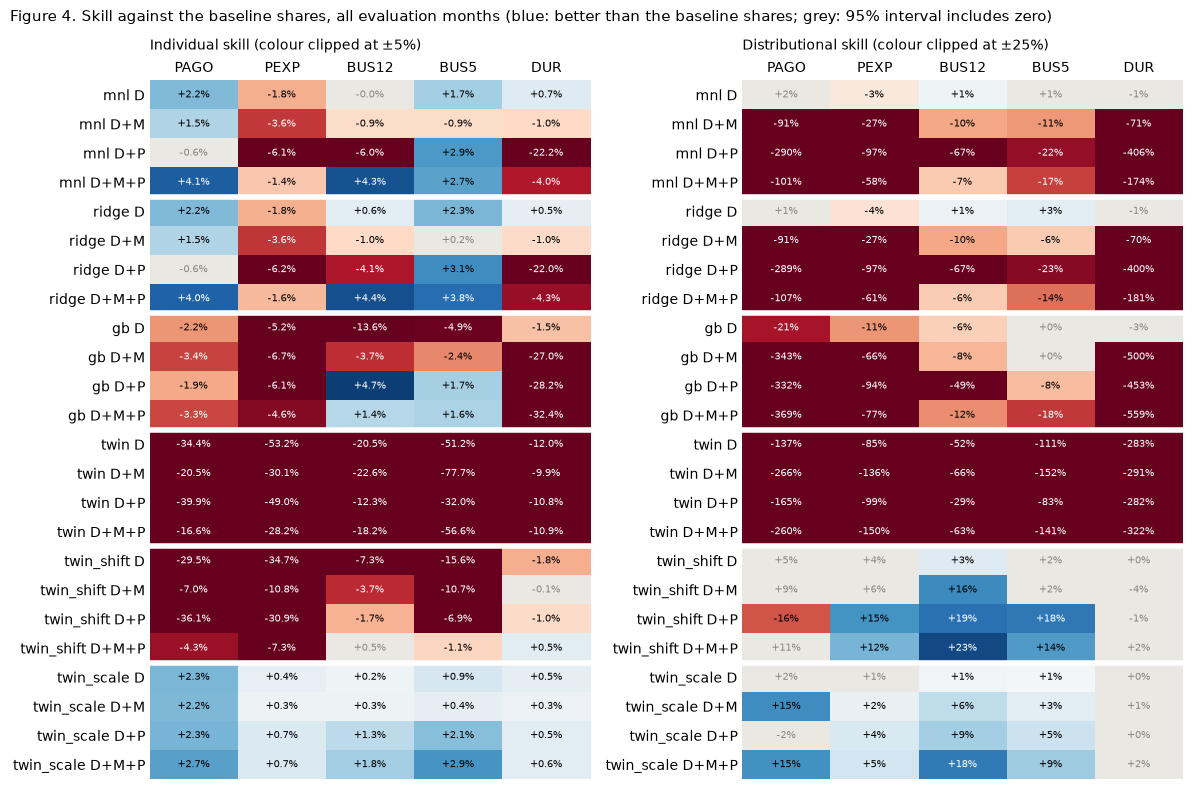

Cells whose skill interval lies above / below zero:
  zero-shot twins (20 cells): distributional 0 / 20, individual 0 / 20
  shifted twins (20 cells): distributional 8 / 1, individual 1 / 17
  scaled twins (20 cells): distributional 13 / 0, individual 20 / 0
  supervised models (60 cells): distributional 3 / 49, individual 21 / 35
log_loss: supervised skill bounds moved by up to 0.2 points from notebook 04; cells whose interval changed sides of zero: 0
wasserstein: supervised skill bounds moved by up to 5.8 points from notebook 04; cells whose interval changed sides of zero: 0


In [11]:
def heat(ax, M, vmax, fmt, cmap, grey=None):
    """Annotated heatmap with colour clipped at ±vmax; cells where `grey` is True are drawn grey."""
    rgba = plt.get_cmap(cmap)((np.clip(M, -vmax, vmax) + vmax) / (2 * vmax))
    if grey is not None:
        rgba[grey] = to_rgba('#e9e8e3')
    ax.imshow(rgba, aspect='auto')
    for (r, c), v in np.ndenumerate(M):
        g = grey is not None and grey[r, c]
        ax.text(c, r, fmt.format(v), ha='center', va='center', fontsize=7.5,
                color='#898781' if g else 'white' if abs(np.clip(v, -vmax, vmax)) > 0.65 * vmax else 'black')
    ax.tick_params(length=0); ax.spines[:].set_visible(False); ax.xaxis.tick_top()

rows = [(f, fs) for f in ['mnl', 'ridge', 'gb', 'twin', 'twin_shift', 'twin_scale'] for fs in SHORT]
fig, axes = plt.subplots(1, 2, figsize=(12, 8))
for ax, (s, title, vmax, fmt) in zip(axes, [('log_loss_skill', 'Individual skill', 0.05, '{:+.1%}'),
                                            ('wasserstein_skill', 'Distributional skill', 0.25, '{:+.0%}')]):
    grid = lambda col: np.array([[allc.loc[(f'{f}_{fs}', i), col] for i in ITEMS] for f, fs in rows])
    heat(ax, grid(s), vmax, fmt, 'RdBu', grey=(grid(f'{s}_lo') <= 0) & (grid(f'{s}_hi') >= 0))
    ax.set_xticks(range(len(ITEMS)), ITEMS); ax.set_yticks(range(len(rows)), [f'{f} {SHORT[fs]}' for f, fs in rows])
    for y in np.arange(3.5, len(rows) - 1, 4):
        ax.axhline(y, color='white', lw=4)
    ax.set_title(f'{title} (colour clipped at ±{vmax:.0%})', loc='left', fontsize=10, pad=22)
fig.suptitle('Figure 4. Skill against the baseline shares, all evaluation months (blue: better than the baseline shares; '
             'grey: 95% interval includes zero)', x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

groups = {'zero-shot twins': [f'twin_{fs}' for fs in SHORT], 'shifted twins': [f'twin_shift_{fs}' for fs in SHORT],
          'scaled twins': [f'twin_scale_{fs}' for fs in SHORT], 'supervised models': SUPERVISED_MODELS}
print('Cells whose skill interval lies above / below zero:')
for name, models_ in groups.items():
    x = allc.loc[models_]
    print(f'  {name} ({len(x)} cells): distributional {(x.wasserstein_skill_lo > 0).sum()} / '
          f'{(x.wasserstein_skill_hi < 0).sum()}, individual {(x.log_loss_skill_lo > 0).sum()} / {(x.log_loss_skill_hi < 0).sum()}')
old = pd.read_csv(SUPERVISED / 'scores.csv').query("period == 'all' and group == 'all'").set_index(['model', 'item'])
old = old[old.log_loss_skill.notna()]
new = allc.loc[old.index]
for s in ['log_loss', 'wasserstein']:
    b = [f'{s}_skill_lo', f'{s}_skill_hi']
    flips = (((old[b[0]] > 0) | (old[b[1]] < 0)) != ((new[b[0]] > 0) | (new[b[1]] < 0))).sum()
    print(f'{s}: supervised skill bounds moved by up to {100 * (new[b] - old[b]).abs().max().max():.1f} points '
          f'from notebook 04; cells whose interval changed sides of zero: {flips}')

On answer shares, the calibrated twins often beat the baseline shares and almost never lose to them, whereas the
supervised models almost never beat them and usually lose. By intervals that exclude zero, the calibrated twins beat the
baseline shares in 21 of their 40 cells and lose in 1; the supervised models beat them in 3 of their 60 cells and lose
in 49.

On individual answers, only the scaled twins beat the baseline shares consistently. They beat them in all 20 of their
cells, whereas the shifted twins beat them in 1 and lose in 17, and the supervised models beat them in 21 of their 60
cells and lose in 35.

Of the three twins, the zero-shot twin loses to the baseline shares in every cell on both scores, because it starts far
from the answer shares (section 1.1), so calibration is what makes the twin competitive. Between the two calibrations,
the scaled twin is the stronger on individual answers, where it beats the baseline shares in 20 cells against the
shifted twin's 1. On answer shares the two are closer: the scaled twin clears the baseline shares in more cells, 13
against 8, but on D+M+P the shifted twin comes closer to the actual shares on three items (section 8.2).

Because notebook 04 drew each item separately, its supervised skill bounds differ from these by up to 5.8 points, though
no interval changes sides of zero.

## 7. Calibrated twins against supervised models on answer shares

Figure 4 singles out the calibrated twins on answer shares. This section compares the two twins on D+M+P in three steps:
with the supervised models on the same inputs, with the best supervised model on each item, and with the baseline
shares. It then traces the comparison to the state variables: overall (8.1), by period (8.2) and by party (8.3). Figure
5 places every model's distance from the actual answer shares on one line per item, together with the band from the
noise floor, the distance that a model knowing each month's true shares would still have (notebook 03, section 2.3), to
the baseline shares:

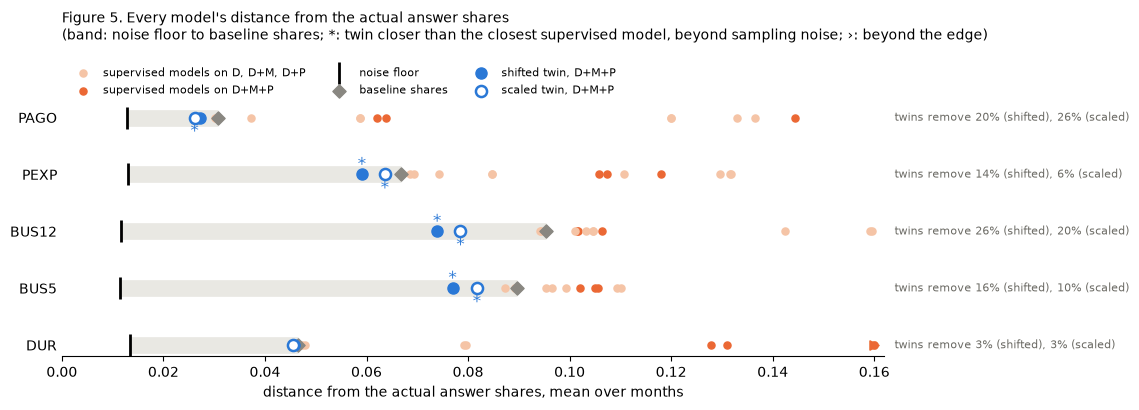

In [12]:
CAL = [TWIN, SCALED]
extra = bootstrap(pred[pred.model.isin(CAL + SUPERVISED_MODELS + ['baseline'])], test,
                  pairs=[(t, s) for t in CAL for s in SUPERVISED_MODELS] + [(TWIN, SCALED)],
                  draws=draws).set_index(['model', 'item'])
bounds = extra.loc[[f'{TWIN}-{LOGIT}', f'{SCALED}-{LOGIT}'], ['wasserstein_lo', 'wasserstein_hi', 'log_loss_lo', 'log_loss_hi']]
assert np.allclose(bounds, allc.loc[bounds.index, bounds.columns], atol=1e-6)       # the scoring run's intervals
beats = lambda t, s, i: extra.loc[(f'{t}-{s}', i), 'wasserstein_hi'] < 0           # t closer than s beyond noise

dist = lambda m: allc.xs(m, level='model').wasserstein.loc[ITEMS]
floor, base = dist('floor'), dist('baseline')
same = [f'{f}_{DMP}' for f in ['mnl', 'ridge', 'gb']]
closest = {i: min(SUPERVISED_MODELS, key=lambda s: dist(s)[i]) for i in ITEMS}    # the supervised models' best, by item
# Claim checks: each twin beats each supervised model on D+M+P on every item, beyond sampling noise; the closest
# supervised model is the logit or ridge on D on every item, and the twins beat it beyond sampling noise on PEXP, BUS12
# and BUS5, and the scaled twin on PAGO
assert all(beats(t, s, i) for t in CAL for s in same for i in ITEMS)
assert set(closest.values()) <= {'mnl_demographics', 'ridge_demographics'}
assert [[i for i in ITEMS if beats(t, closest[i], i)] for t in CAL] == [ITEMS[1:4], ITEMS[:4]]

EDGE = 0.16                                      # distances beyond it are drawn at the edge as ›
fig, ax = plt.subplots(figsize=(11.5, 4.2))
for y, item in enumerate(ITEMS):
    ax.plot([floor[item], base[item]], [y, y], color='#e9e8e3', lw=12, solid_capstyle='butt', zorder=1)
    removed = ', '.join(f'{(base[item] - dist(t)[item]) / (base[item] - floor[item]):.0%} ({NAMES[t].split()[0]})' for t in CAL)
    ax.text(EDGE + 0.004, y, f'twins remove {removed}', va='center', fontsize=8, color='#6b6a64')
for s in SUPERVISED_MODELS:
    x, color = dist(s), ('#eb6834' if s.endswith(DMP) else '#f5c4a6')
    ax.scatter(x.clip(upper=EDGE).values, range(len(ITEMS)), s=26, color=color, zorder=2,
               marker='o', label=None)
    out = x > EDGE
    ax.scatter(np.full(out.sum(), EDGE), np.flatnonzero(out), s=40, color=color, marker='>', zorder=2)
ax.scatter([], [], s=26, color='#f5c4a6', label='supervised models on D, D+M, D+P')
ax.scatter([], [], s=26, color='#eb6834', label='supervised models on D+M+P')
ax.scatter(floor.values, range(len(ITEMS)), marker='|', color='black', s=240, linewidths=2, zorder=3, label='noise floor')
ax.scatter(base.values, range(len(ITEMS)), marker='D', color='#898781', s=45, zorder=3, label='baseline shares')
ax.scatter(dist(TWIN).values, range(len(ITEMS)), marker='o', color='#2a78d6', s=64, zorder=4, label='shifted twin, D+M+P')
ax.scatter(dist(SCALED).values, range(len(ITEMS)), marker='o', facecolors='white', edgecolors='#2a78d6', s=64,
           linewidths=1.8, zorder=4, label='scaled twin, D+M+P')
for k, t in enumerate(CAL):                      # *: beats the closest supervised model beyond sampling noise
    for y, item in enumerate(ITEMS):
        if beats(t, closest[item], item):
            ax.annotate('*', (dist(t)[item], y), xytext=(-3, 4 if k == 0 else -13), textcoords='offset points',
                        fontsize=12, color='#2a78d6')
ax.set_yticks(range(len(ITEMS)), ITEMS); ax.invert_yaxis(); ax.set_xlim(0, EDGE + 0.002)
ax.set_xlabel('distance from the actual answer shares, mean over months')
ax.spines[['top', 'right', 'left']].set_visible(False); ax.tick_params(axis='y', length=0)
ax.legend(frameon=False, fontsize=8, ncol=3, loc='lower left', bbox_to_anchor=(0, 1.0))
ax.set_title('Figure 5. Every model\'s distance from the actual answer shares\n(band: noise floor to baseline shares; '
             '*: twin closer than the closest supervised model, beyond sampling noise; ›: beyond the edge)',
             loc='left', fontsize=10, pad=48)
plt.tight_layout(); plt.show()

**Given the state, the calibrated twins beat every supervised model on the same inputs.** On every item, both twins on
D+M+P lie closer to the actual shares than the logit, ridge and boosting on D+M+P, and all 30 of these paired
differences exclude zero.

**They also beat the best supervised model on each item.** On every item the closest supervised model is the logit or
ridge on D, and both twins lie closer than it, beyond sampling noise on `PEXP`, `BUS12` and `BUS5`, and on `PAGO` for
the scaled twin (the stars).

**Against the baseline shares, their lead is real but modest.** Both twins lie inside the band on every item, beyond
sampling noise on three items (shifted) or four (scaled) (Figure 4), but near its baseline end: they remove at most 26%
of the baseline shares' distance above the floor.

### 7.1 Why: the state variables

Figure 6 follows each model's distance from the actual shares from D to D+M+P:

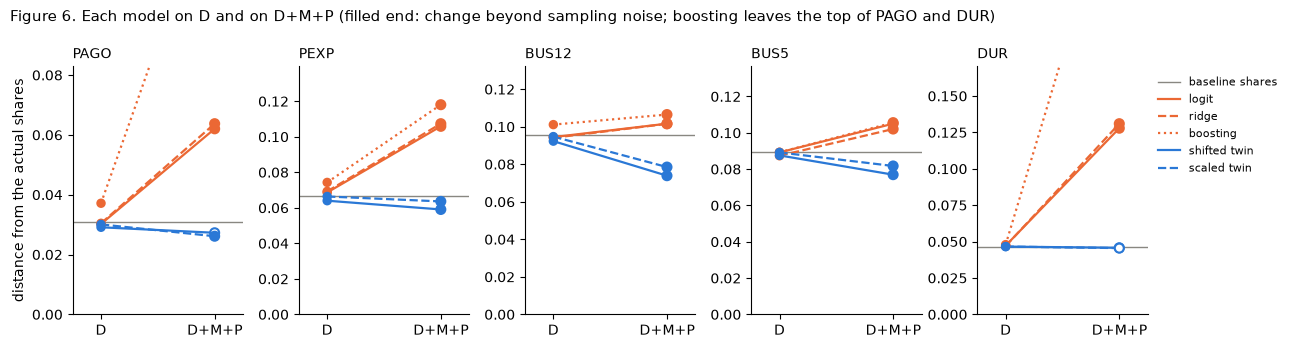

In [13]:
FAMILIES = {'mnl': 'logit', 'ridge': 'ridge', 'gb': 'boosting', 'twin_shift': 'shifted twin', 'twin_scale': 'scaled twin'}
STYLE = {'mnl': dict(color='#eb6834', ls='-'), 'ridge': dict(color='#eb6834', ls='--'), 'gb': dict(color='#eb6834', ls=':'),
         'twin_shift': dict(color='#2a78d6', ls='-'), 'twin_scale': dict(color='#2a78d6', ls='--')}
sets = ['demographics', DMP]
fig, axes = plt.subplots(1, 5, figsize=(13, 3.5))
for ax, item in zip(axes, ITEMS):
    top = 1.3 * max(allc.loc[(f'{f}_{fs}', item), 'wasserstein'] for f in FAMILIES if f != 'gb' for fs in sets)
    ax.axhline(base[item], color='#898781', lw=1, label='baseline shares')
    for f, st in STYLE.items():
        y = [allc.loc[(f'{f}_{fs}', item), 'wasserstein'] for fs in sets]
        d = cell.loc[('all', 'all', f'{f}_{DMP}-{f}_demographics', item)]
        filled = d.wasserstein_lo > 0 or d.wasserstein_hi < 0           # the change is beyond sampling noise
        ax.plot([0, 1], y, lw=1.6, label=FAMILIES[f], clip_on=True, **st)
        ax.scatter([0, 1], y, s=[28, 42], zorder=3, clip_on=True, linewidths=1.5, edgecolors=st['color'],
                   facecolors=[st['color'], st['color'] if filled else 'white'])
    ax.set_xticks([0, 1], ['D', 'D+M+P']); ax.set_xlim(-0.25, 1.25); ax.set_ylim(0, top)
    ax.set_title(item, loc='left', fontsize=10); ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('distance from the actual shares')
axes[-1].legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
fig.suptitle('Figure 6. Each model on D and on D+M+P (filled end: change beyond sampling noise; boosting leaves the '
             'top of PAGO and DUR)', x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

On D, the twins and the supervised models start at nearly the same distance from the actual shares on every item, except
boosting. The state variables then pull them apart: every supervised model moves away from the actual shares on every
item, whereas the twins move toward them on three items (shifted) or four (scaled). The twins' lead on D+M+P is
therefore created by the state variables. The same move explains the twins' other two leads: on D they start level with
the supervised models on D and with the baseline shares (the grey line), so the state variables, by moving the twins
closer, put them ahead of both.

### 7.2 When: by period

Figure 7 splits the change from D by block of state variables and by period, for the logit and the shifted twin, the two
models of the primary test. A bar above zero means that the block moves the model away from the actual shares:

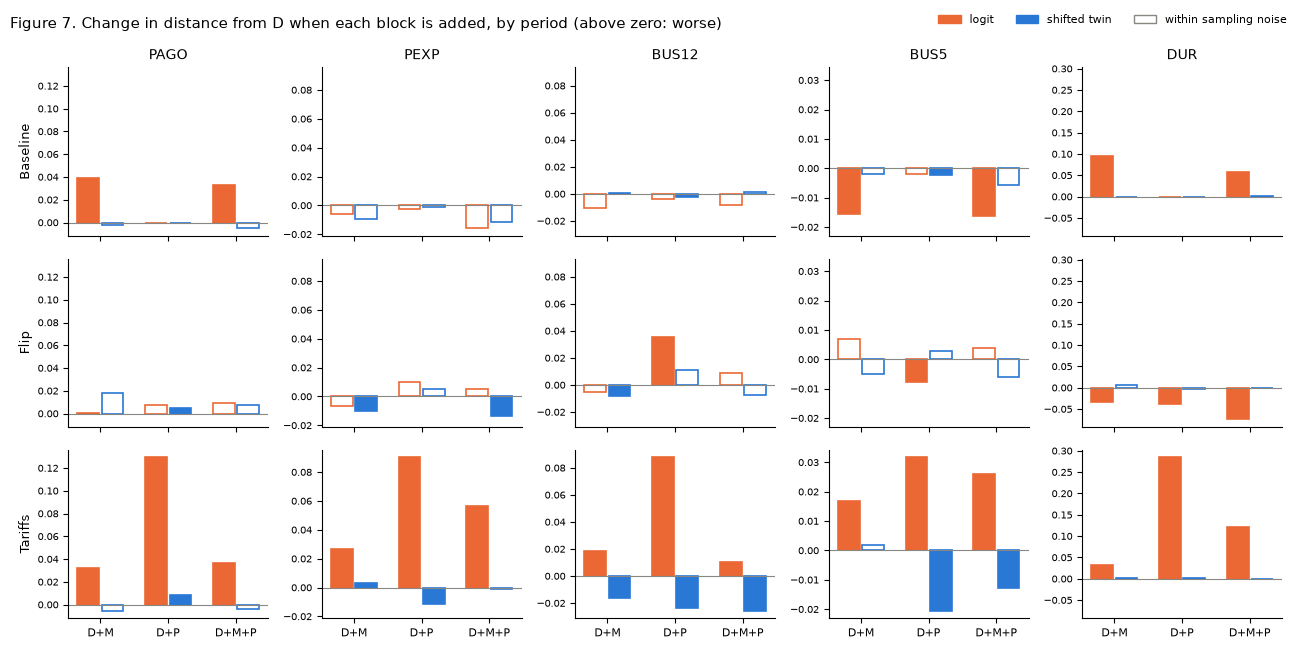

In [14]:
BLOCKS = {'D+M': 'demographics_macro', 'D+P': 'demographics_politics', 'D+M+P': DMP}
PAIR = [('mnl', '#eb6834'), ('twin_shift', '#2a78d6')]

def block_bars(rows, row_key, title):
    """Grid of rows x items: for each block, the change in distance from D of the logit and the shifted twin.
    `rows` maps a row label to the (period, group) cell it reads."""
    fig, axes = plt.subplots(len(rows), len(ITEMS), figsize=(13, 1.9 * len(rows) + 0.8), sharey='col', squeeze=False)
    for r_, (name, (p, g)) in enumerate(rows.items()):
        for c_, item in enumerate(ITEMS):
            ax = axes[r_, c_]
            for b_, fs in enumerate(BLOCKS.values()):
                for k, (f, color) in enumerate(PAIR):
                    x = cell.loc[(p, g, f'{f}_{fs}-{f}_demographics', item)]
                    filled = x.wasserstein_lo > 0 or x.wasserstein_hi < 0
                    ax.bar(b_ + (k - 0.5) * 0.36, x.wasserstein, width=0.32, color=color if filled else 'white',
                           edgecolor=color, linewidth=1.2)
            ax.axhline(0, color='#898781', lw=0.8)
            ax.set_xticks(range(len(BLOCKS)), BLOCKS if r_ == len(rows) - 1 else [''] * len(BLOCKS), fontsize=8)
            ax.tick_params(axis='y', labelsize=7); ax.spines[['top', 'right']].set_visible(False)
            if r_ == 0:
                ax.set_title(item, fontsize=10)
            if c_ == 0:
                ax.set_ylabel(name, fontsize=9)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for _, c in PAIR] + [plt.Rectangle((0, 0), 1, 1, fc='white', ec='#898781')]
    fig.legend(handles, ['logit', 'shifted twin', 'within sampling noise'], frameon=False, fontsize=8, ncol=3,
               loc='upper right', bbox_to_anchor=(1, 1.0))
    fig.suptitle(title, x=0.01, ha='left', fontsize=10.5)
    plt.tight_layout(); plt.show()

block_bars({p: (p, 'all') for p in PERIODS}, 'period',
           'Figure 7. Change in distance from D when each block is added, by period (above zero: worse)')

The divergence comes mostly from the political block, in the tariff months. There, that block worsens the logit on every
item, by more than either other block, and improves the twin on `PEXP`, `BUS12` and `BUS5`. Before the tariff months the
political block matters little for either model: in Baseline the only large effect is the logit's macro block, which
worsens `PAGO` and `DUR` as notebook 04 found, and in Flip the effects are mixed, the logit's gain on `DUR` being the
coincidence of section 4.1. The same input, a Republican president and election winner, thus moved the two models in
opposite directions. The twin's lead over the logit accordingly lies mostly in the tariff months: its mean distance is
lower by 0.010 in Baseline and by 0.063 in the tariff months, and higher by 0.004 in Flip (section 4.2). Because the
political block acts through party, section 7.3 asks what it did to each party.

### 7.3 For whom: by party

The political block tells both models which party governs, and the logit also has party products, which move Republicans
and Democrats in opposite directions. Figure 8 shows what the block did to each party in the tariff months, with each
group's share of respondents in brackets:

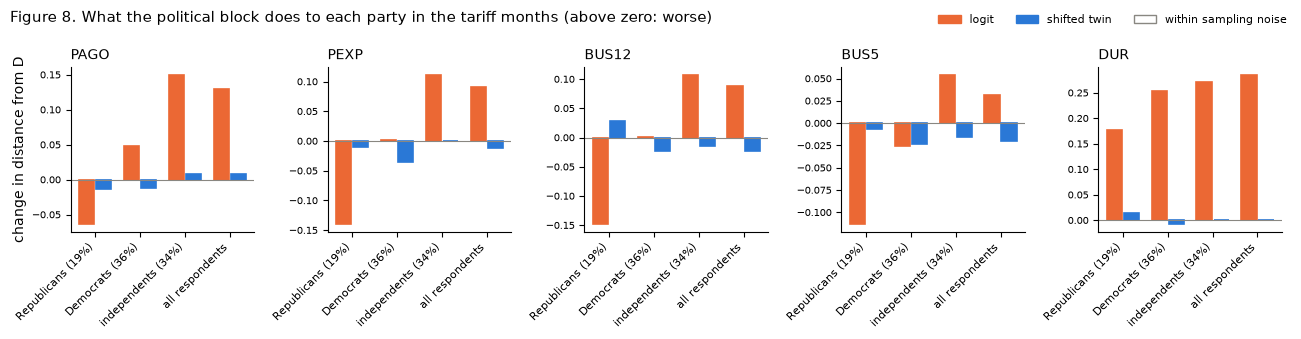

In [15]:
GROUPS = {'Rep': 'Republicans', 'Dem': 'Democrats', 'Ind': 'independents', 'all': 'all respondents'}
q = pred[(pred.YYYYMM >= PERIODS['Tariffs']) & (pred.model == LOGIT)]
w = q[q.item == 'PEXP'].groupby('party').WT.sum()
share = {g: f' ({100 * w[g] / w.sum():.0f}%)' if g in w else '' for g in GROUPS}
fig, axes = plt.subplots(1, len(ITEMS), figsize=(13, 3.4))
for ax, item in zip(axes, ITEMS):
    for x_, g in enumerate(GROUPS):
        for k, (f, color) in enumerate(PAIR):
            d = cell.loc[('Tariffs', g, f'{f}_demographics_politics-{f}_demographics', item)]
            filled = d.wasserstein_lo > 0 or d.wasserstein_hi < 0
            ax.bar(x_ + (k - 0.5) * 0.38, d.wasserstein, width=0.34, color=color if filled else 'white',
                   edgecolor=color, linewidth=1.2)
    ax.axhline(0, color='#898781', lw=0.8)
    ax.set_xticks(range(len(GROUPS)), [f'{n}{share[g]}' for g, n in GROUPS.items()], rotation=45, ha='right', fontsize=8)
    ax.tick_params(axis='y', labelsize=7); ax.spines[['top', 'right']].set_visible(False)
    ax.set_title(item, loc='left', fontsize=10)
axes[0].set_ylabel('change in distance from D')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for _, c in PAIR] + [plt.Rectangle((0, 0), 1, 1, fc='white', ec='#898781')]
fig.legend(handles, ['logit', 'shifted twin', 'within sampling noise'], frameon=False, fontsize=8, ncol=3,
           loc='upper right', bbox_to_anchor=(1, 1.0))
fig.suptitle('Figure 8. What the political block does to each party in the tariff months (above zero: worse)',
             x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

The political block helps the logit only among Republicans, and the twin mainly among Democrats. For the logit, it
improves Republicans on four items, worsens independents on every item, and has mixed effects on Democrats. For the
twin, it improves Democrats on every item and changes the other groups little. On all respondents, the logit's gain
among Republicans, 19% of respondents, is outweighed by its losses among the rest, whereas the twin's gain among
Democrats, the largest group at 36%, carries through.

Figure 9 shows why, for `PEXP` and `BUS12` in the tariff months. For each group it marks the actual net balance and
draws each model's prediction moving from D to D+P, so an arrow that points toward the actual is an improvement:

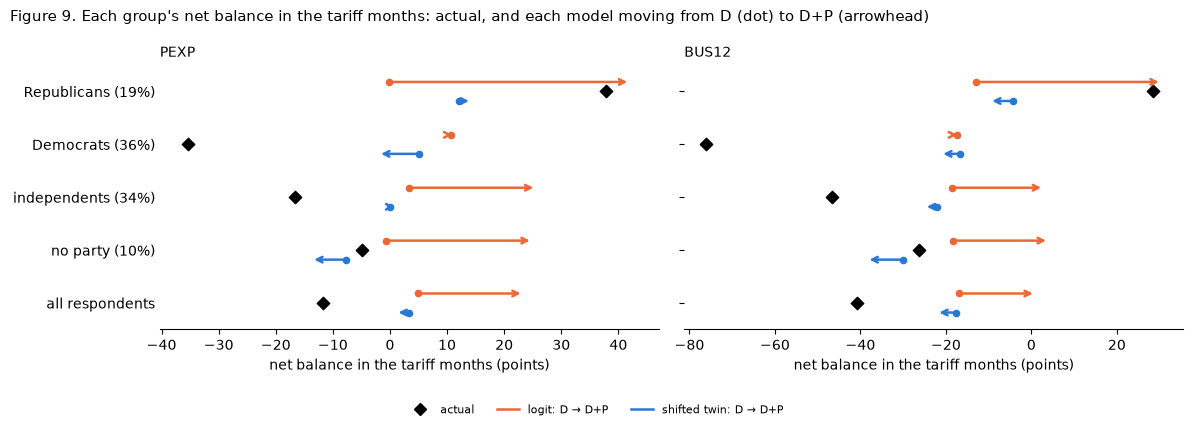

In [16]:
# Each group's net balance in the tariff months: actual, and each model's prediction on D and on D+P
PAIR_DP = {'mnl': ('logit', '#eb6834'), 'twin_shift': ('shifted twin', '#2a78d6')}
groups = {'Rep': 'Republicans', 'Dem': 'Democrats', 'Ind': 'independents', 'none': 'no party', 'all': 'all respondents'}

def level(g, m):
    """Weighted net balance of the interviews g: actual, or predicted by model m."""
    if m == 'actual':
        g = g[g.model == 'baseline']
        return 100 * np.average(g.actual_fav.astype(float) - g.actual_unf, weights=g.WT)
    g = g[g.model == m]
    return 100 * np.average(g.fav - g.unf, weights=g.WT)

tariffs = pred[pred.YYYYMM >= PERIODS['Tariffs']]
w = tariffs[(tariffs.model == LOGIT) & (tariffs.item == 'PEXP')].groupby('party').WT.sum()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, item in zip(axes, ['PEXP', 'BUS12']):
    q, xs = tariffs[tariffs.item == item], []
    for y, g in enumerate(groups):
        sub = q if g == 'all' else q[q.party == g]
        xs.append(level(sub, 'actual'))
        ax.scatter([xs[-1]], [y], marker='D', s=40, color='black', zorder=3)
        for k, (f, (_, color)) in enumerate(PAIR_DP.items()):
            d, dp, yy = level(sub, f'{f}_demographics'), level(sub, f'{f}_demographics_politics'), y + (k - 0.5) * 0.36
            ax.annotate('', xy=(dp, yy), xytext=(d, yy), arrowprops=dict(arrowstyle='->', color=color, lw=1.8))
            ax.scatter([d], [yy], s=20, color=color, zorder=3)
            xs += [d, dp]
    ax.set_xlim(min(xs) - 5, max(xs) + 5)        # arrows do not enter autoscaling
    ax.set_title(item, loc='left', fontsize=10); ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.set_xlabel('net balance in the tariff months (points)')
axes[0].set_yticks(range(len(groups)), [f'{n} ({100 * w[g] / w.sum():.0f}%)' if g in w else n for g, n in groups.items()])
axes[0].tick_params(axis='y', length=0); axes[0].set_ylim(len(groups) - 0.5, -0.5)
fig.suptitle('Figure 9. Each group\'s net balance in the tariff months: actual, and each model moving from D (dot) to '
             'D+P (arrowhead)', x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(rect=(0, 0.08, 1, 1))
fig.legend([plt.Line2D([], [], marker='D', ls='', color='black')] +
           [plt.Line2D([], [], color=c, lw=1.8) for _, c in PAIR_DP.values()],
           ['actual'] + [f'{n}: D → D+P' for n, _ in PAIR_DP.values()], frameon=False, fontsize=8, ncol=3,
           loc='lower center')
plt.show()

The logit's political block has two parts. Its main effects raise every group by the same amount: independents and
respondents who report no party, who have no party product, move up by 21 to 26 points, away from their actual answers.
Its party products then add a further rise for Republicans and, for Democrats, a fall that cancels the common rise. The
rise is right for Republicans, whose answers lie far above the logit's prediction on D, and wrong for everyone else. The
twin's political block has no common rise: it lowers Democrats by 5 to 7 points, toward their actual answers, and moves
the other groups by at most 8 points.

The common rise is confounding (preamble). The training window holds one Republican presidency, so the logit's function
attributes to a Republican president the optimism that came with the other conditions of the first Trump presidency
(notebook 04, section 5.3), and in the tariff months it applies that optimism to every group. The twin's function comes
from general knowledge, which does not make everyone optimistic under a Republican president, so it has no such rise.
Neither function predicts the fall in answers, whose causes appear in no input, most visibly the tariffs.

The party products are where the political block helps the logit: with them it separates Republicans from Democrats
further than the twin does, and closer to their answers (section 4.1). The answer shares of all respondents do not score
how well a model tells respondents apart, because they average over them. Section 8 turns to individual answers, which
do.

## 8. Individual answers

Figure 10 takes section 7's three steps on the individual score. It places the skill of every supervised model and of
the two calibrated twins on D+M+P on one line per item, against the baseline shares at zero:

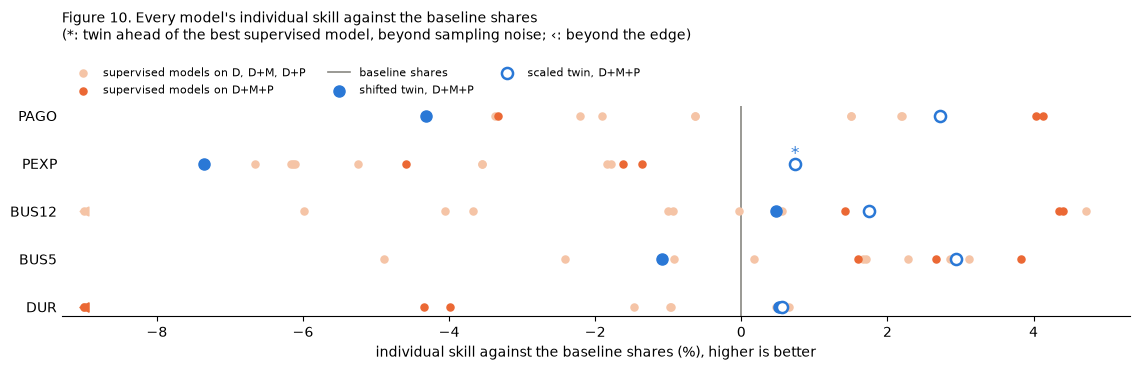

In [17]:
# Individual skill against the baseline shares, in percent: every supervised model and the calibrated twins on D+M+P
skill = lambda m: 100 * allc.xs(m, level='model').log_loss_skill.loc[ITEMS]
ahead = lambda t, s, i: extra.loc[(f'{t}-{s}', i), 'log_loss_hi'] < 0            # t predicts better than s beyond noise
behind = lambda t, s, i: extra.loc[(f'{t}-{s}', i), 'log_loss_lo'] > 0
best = {i: max(SUPERVISED_MODELS, key=lambda s: skill(s)[i]) for i in ITEMS}      # the supervised models' best, by item
# Claim checks, by intervals that exclude zero. Same inputs: against the supervised models on D+M+P the scaled twin is
# ahead in 8 and behind in 5 of the 15 comparisons, and the shifted twin is behind in 11 and ahead only on DUR. Best
# supervised model: the scaled twin is behind it on three items and ahead on PEXP, and the shifted twin is behind it
# on four. Baseline shares: the scaled twin is above them on every
# item, and the shifted twin is below them on three.
count = lambda test, t: sum(test(t, s, i) for s in same for i in ITEMS)
assert (count(ahead, SCALED), count(behind, SCALED), count(behind, TWIN)) == (8, 5, 11)
assert {i for s in same for i in ITEMS if ahead(TWIN, s, i)} == {'DUR'}
assert {i for i in ITEMS if behind(SCALED, best[i], i)} == {'PAGO', 'BUS12', 'BUS5'}
assert {i for i in ITEMS if ahead(SCALED, best[i], i)} == {'PEXP'}
assert {i for i in ITEMS if behind(TWIN, best[i], i)} == {'PAGO', 'PEXP', 'BUS12', 'BUS5'}
assert all(allc.loc[(SCALED, i), 'log_loss_skill_lo'] > 0 for i in ITEMS)
assert {i for i in ITEMS if allc.loc[(TWIN, i), 'log_loss_skill_hi'] < 0} == {'PAGO', 'PEXP', 'BUS5'}

EDGE = -9                                        # skills below it are drawn at the edge as ‹
fig, ax = plt.subplots(figsize=(11.5, 3.8))
ax.axvline(0, color='#898781', lw=1.2, zorder=1)
for s in sorted(SUPERVISED_MODELS, key=lambda s: s.endswith(DMP)):                # D+M+P last, so drawn on top
    x, color = skill(s), ('#eb6834' if s.endswith(DMP) else '#f5c4a6')
    ax.scatter(x.clip(lower=EDGE).values, range(len(ITEMS)), s=26, color=color, zorder=2)
    out = x < EDGE
    ax.scatter(np.full(out.sum(), EDGE), np.flatnonzero(out), s=40, color=color, marker='<', zorder=2)
ax.scatter([], [], s=26, color='#f5c4a6', label='supervised models on D, D+M, D+P')
ax.scatter([], [], s=26, color='#eb6834', label='supervised models on D+M+P')
ax.plot([], [], color='#898781', lw=1.2, label='baseline shares')
ax.scatter(skill(TWIN).values, range(len(ITEMS)), marker='o', color='#2a78d6', s=64, zorder=4, label='shifted twin, D+M+P')
ax.scatter(skill(SCALED).values, range(len(ITEMS)), marker='o', facecolors='white', edgecolors='#2a78d6', s=64,
           linewidths=1.8, zorder=4, label='scaled twin, D+M+P')
for t in CAL:                                    # *: ahead of the best supervised model beyond sampling noise
    for y, item in enumerate(ITEMS):
        if ahead(t, best[item], item):
            ax.annotate('*', (skill(t)[item], y), xytext=(-3, 4), textcoords='offset points', fontsize=12, color='#2a78d6')
ax.set_yticks(range(len(ITEMS)), ITEMS); ax.invert_yaxis()
ax.set_xlim(EDGE - 0.3, max(skill(m).max() for m in SUPERVISED_MODELS + CAL) + 0.6)
ax.set_xlabel('individual skill against the baseline shares (%), higher is better')
ax.spines[['top', 'right', 'left']].set_visible(False); ax.tick_params(axis='y', length=0)
ax.legend(frameon=False, fontsize=8, ncol=3, loc='lower left', bbox_to_anchor=(0, 1.0))
ax.set_title('Figure 10. Every model\'s individual skill against the baseline shares\n'
             '(*: twin ahead of the best supervised model, beyond sampling noise; ‹: beyond the edge)',
             loc='left', fontsize=10, pad=48)
plt.tight_layout(); plt.show()

**Given the state, the scaled twin predicts about as well as the supervised models on the same inputs, and the shifted
twin predicts worse.** Against the logit, ridge and boosting on D+M+P, the scaled twin is ahead in 8 of the 15
comparisons and behind in 5, by paired intervals that exclude zero. The shifted twin is behind in 11 and ahead only on
`DUR`.

**Against the best supervised model on each item, the scaled twin is behind on three items and the shifted twin on
four.** The scaled twin is ahead of it only on `PEXP` (the star), and neither twin is separated from it on `DUR`.

**Against the baseline shares, the scaled twin leads on every item and the shifted twin trails on three.** The shifted
twin is above them only on `DUR`.

Section 8.1 asks why the twins' lead on answer shares does not carry over to individual answers, and section 8.2 why the
two twins differ so much.

### 8.1 Level and differences

An individual prediction is a level plus a difference. The level is the model's mean prediction for the month, which is
its predicted answer shares, so section 7 scored the level alone. The difference is the respondent's departure from the
level. Skill splits the same way: the skill of the level is the model's skill when every respondent is given the level,
the skill of the differences is the rest, and the two sum to the model's skill. Figure 11 follows the two parts and
their sum from D to D+M+P, averaged over the five items. A level at zero matches the baseline shares, and differences at
zero add nothing to the level:

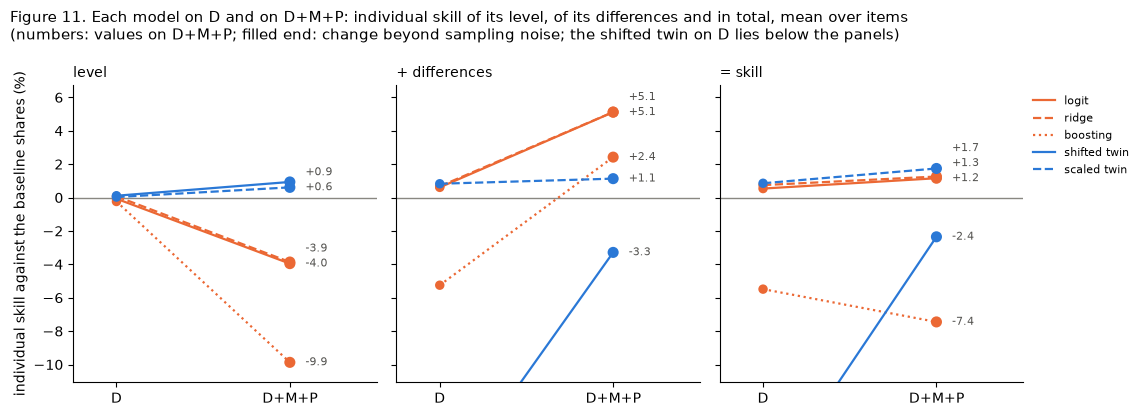

In [18]:
def parts(models, months=None):
    """Skill of each model's level and of its differences, per item, in percent of the baseline shares' log loss. The
    level is the model's weighted mean prediction for the month, given to every respondent, and the differences earn
    the rest of the model's skill. Row 0 is the sample and each later row a bootstrap draw of section 7, on which the
    level is taken from the draw's respondents. `months` keeps only those survey months."""
    out = {}
    for item in ITEMS:
        b = pred[(pred.model == 'baseline') & (pred.item == item)]
        b = b if months is None else b[b.YYYYMM.isin(months)]
        ids, w, month = b.CASEID.to_numpy(), b.WT.to_numpy(float), b.YYYYMM.to_numpy()
        y = np.where(b.actual_fav, 0, np.where(b.actual_unf, 2, 1))            # position of each answer in CLASSES
        counts = draws.loc[ids].to_numpy().T
        P = {m: np.clip(pred[(pred.model == m) & (pred.item == item)].set_index('CASEID').loc[ids, CLASSES].to_numpy(),
                        1e-15, 1) for m in ['baseline', *models]}
        loss, level = {m: 0 for m in P}, {m: 0 for m in P}
        for t in np.unique(month):
            s = month == t
            cw = np.vstack([np.ones(s.sum()), counts[:, s]]) * w[s]            # each row's weight on each respondent
            answered = cw @ np.eye(3)[y[s]]                                    # each row's weight on each answer
            for m in P:
                loss[m] = loss[m] + cw @ -np.log(P[m][s][np.arange(s.sum()), y[s]])
                level[m] = level[m] + (answered * -np.log(cw @ P[m][s] / cw.sum(axis=1, keepdims=True))).sum(axis=1)
        for m in models:
            out[m, item, 'level'] = 100 * (1 - level[m] / loss['baseline'])
            out[m, item, 'differences'] = 100 * (level[m] - loss[m]) / loss['baseline']
    return pd.DataFrame(out)

S = parts([f'{f}_{fs}' for f in FAMILIES for fs in sets] + ['mnl_demographics_macro', 'mnl_demographics_politics'])
change = {(f, item, part): S[f'{f}_{DMP}', item, part] - S[f'{f}_demographics', item, part]
          for f in FAMILIES for item in ITEMS for part in ['level', 'differences']}
beyond = {k: (lambda lo, hi: lo > 0 or hi < 0)(*np.percentile(d.iloc[1:], [2.5, 97.5])) for k, d in change.items()}
# Claim checks by item: from D to D+M+P, beyond sampling noise, the level of every supervised model falls on every item
# but one and its differences gain on every item; neither twin's level falls on any item; the scaled twin's differences
# change by at most 1.1 points
supervised = ['mnl', 'ridge', 'gb']
assert sum(beyond[f, i, 'level'] and change[f, i, 'level'].iloc[0] < 0 for f in supervised for i in ITEMS) == 14
assert all(beyond[f, i, 'differences'] and change[f, i, 'differences'].iloc[0] > 0 for f in supervised for i in ITEMS)
assert all(change[f, i, 'level'].iloc[0] > 0 for f in ['twin_shift', 'twin_scale'] for i in ITEMS)
assert max(abs(change['twin_scale', i, 'differences'].iloc[0]) for i in ITEMS) < 1.15

# Means over the five items, on the sample (row 0) and on every draw; a model's skill is the sum of its two parts
M = {(f, fs, part): pd.concat([S[f'{f}_{fs}', i, part] for i in ITEMS], axis=1).mean(axis=1)
     for f in FAMILIES for fs in sets for part in ['level', 'differences']}
M |= {(f, fs, 'skill'): M[f, fs, 'level'] + M[f, fs, 'differences'] for f in FAMILIES for fs in sets}
PANELS = {'level': 'level', 'differences': '+ differences', 'skill': '= skill'}
ends = {part: {f: M[f, DMP, part].iloc[0] for f in FAMILIES} for part in PANELS}
low, high = min(min(e.values()) for e in ends.values()), max(max(e.values()) for e in ends.values())
fig, axes = plt.subplots(1, 3, figsize=(11.5, 4.2), sharey=True)
for ax, (part, title) in zip(axes, PANELS.items()):
    ax.axhline(0, color='#898781', lw=1)
    for f, st in STYLE.items():
        y = [M[f, fs, part].iloc[0] for fs in sets]
        lo, hi = np.percentile((M[f, DMP, part] - M[f, 'demographics', part]).iloc[1:], [2.5, 97.5])
        ax.plot([0, 1], y, lw=1.6, label=FAMILIES[f], clip_on=True, **st)
        ax.scatter([0, 1], y, s=[28, 42], zorder=3, clip_on=True, linewidths=1.5, edgecolors=st['color'],
                   facecolors=[st['color'], st['color'] if lo > 0 or hi < 0 else 'white'])
    at = None                                    # label each end on D+M+P, moved apart where two would overlap
    for f in sorted(ends[part], key=ends[part].get):
        at = ends[part][f] if at is None else max(ends[part][f], at + 0.9)
        ax.text(1.09, at, f'{ends[part][f]:+.1f}', va='center', fontsize=8, color='#52514e')
    ax.set_xticks([0, 1], ['D', 'D+M+P']); ax.set_xlim(-0.25, 1.5); ax.set_ylim(low - 1.2, high + 1.6)
    ax.set_title(title, loc='left', fontsize=10); ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('individual skill against the baseline shares (%)')
axes[-1].legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
fig.suptitle('Figure 11. Each model on D and on D+M+P: individual skill of its level, of its differences and in total, '
             'mean over items\n(numbers: values on D+M+P; filled end: change beyond sampling noise; the shifted twin on D '
             'lies below the panels)', x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

# Claim checks for the numbers that sections 8.1 and 8.2 cite, as means over the five items. From D to D+M+P: the change
# in each part and in skill for the logit and the scaled twin, and in skill for ridge and boosting. The logit's
# differences on each feature set, which gain from the political block alone. On D+M+P, each twin's parts and skill, and
# on D the shifted twin's differences.
near = lambda x, v: np.allclose(x, v, atol=0.05)
moved = lambda f, part: (M[f, DMP, part] - M[f, 'demographics', part]).iloc[0]
assert near([moved('mnl', p) for p in PANELS], [-3.9, 4.5, 0.6]) and near([moved('twin_scale', p) for p in PANELS], [0.6, 0.3, 0.9])
assert near([moved('ridge', 'skill'), moved('gb', 'skill')], [0.5, -2.0])
mean = S.iloc[0].groupby(level=[0, 2]).mean()
assert near([mean[f'mnl_{fs}', 'differences'] for fs in SHORT], [0.6, 0.7, 4.7, 5.1])
assert near([ends[p]['twin_shift'] for p in PANELS], [0.9, -3.3, -2.4]) and near([ends[p]['twin_scale'] for p in PANELS], [0.6, 1.1, 1.7])
# By period: the logit's differences are worth more than the scaled twin's in every period, beyond sampling noise; the
# logit's level is within 0.5 points of zero in Baseline and in Flip and below -5 in the tariff months; and the scaled
# twin's skill is below the logit's in Baseline and in Flip and above it in the tariff months, beyond sampling noise
first = months.index.map(period)
sign = lambda d: np.sign(d.iloc[0]) if np.sign(np.percentile(d.iloc[1:], 2.5)) == np.sign(np.percentile(d.iloc[1:], 97.5)) else 0
for p, lead in [('Baseline', -1), ('Flip', -1), ('Tariffs', 1)]:
    R = parts([LOGIT, SCALED], months.index[first == p])
    part = lambda m, k: pd.concat([R[m, i, k] for i in ITEMS], axis=1).mean(axis=1)
    assert sign(part(LOGIT, 'differences') - part(SCALED, 'differences')) == 1
    assert part(LOGIT, 'level').iloc[0] < -5 if p == 'Tariffs' else abs(part(LOGIT, 'level').iloc[0]) < 0.5
    assert sign(part(SCALED, 'level') + part(SCALED, 'differences') - part(LOGIT, 'level') - part(LOGIT, 'differences')) == lead
# The range of the fitted scale a on D+M+P; each twin's monthly net balance, which moves less for the scaled twin on every
# item and a quarter to a half as far as the actual one for the shifted twin on PEXP, BUS12 and BUS5; and the items on
# which the shifted twin is closer than the scaled twin on answer shares, beyond sampling noise
a = [json.load(open(TWINS / 'calibration.json'))['scale'][DMP][i]['a'] for i in ITEMS]
assert near([min(a), max(a)], [0.30, 0.95])
moves = {i: net_balance(i, CAL).std() for i in ITEMS}              # how far each twin's monthly net balance moves
assert all(moves[i][SCALED] < moves[i][TWIN] for i in ITEMS)
assert all(0.25 <= moves[i][TWIN] / moves[i]['actual'] <= 0.5 for i in ['PEXP', 'BUS12', 'BUS5'])
assert [i for i in ITEMS if extra.loc[(f'{TWIN}-{SCALED}', i), 'wasserstein_hi'] < 0] == ['PEXP', 'BUS12', 'BUS5']

The state lowers the level of every supervised model and raises its differences: for the logit by 3.9 and 4.5 points, a
net gain of 0.6 (ridge gains 0.5, and boosting loses 2.0). The lower level is section 7's loss on answer shares. The
higher differences come from the political block, whose party products tell Republicans from Democrats according to who
governs. The state raises both parts of the scaled twin, by 0.6 and 0.3 points, a gain of 0.9.

On individual answers the state therefore improves the logit, ridge and the scaled twin by about the same amount. The
twins' lead on answer shares does not carry over, because answer shares count only the level.

By period, the logit's lead on differences holds throughout and its loss on the level comes almost entirely in the
tariff months (section 7.2), so the scaled twin trails the logit in Baseline and Flip and leads only in the tariff
months.

### 8.2 Shifted against scaled

The shifted twin falls behind through its differences. On D+M+P its level is worth 0.9 points and its differences cost
3.3, so its skill is −2.4. The scaled twin differs from it in one number, the factor a that multiplies its log-odds
(section 1.1). The fitted a is 0.30 to 0.95, so the scaled twin's differences are smaller, and they add 1.1 points to a
level worth 0.6, for a skill of 1.7. The twin's differences therefore have the right direction and are too large.

A factor below 1 shrinks not only the twin's differences but also how far its level moves from month to month. On
`PEXP`, `BUS12` and `BUS5` the shifted twin's level already moved too little in the evaluation window: its net balance
moved a quarter to a half as far as the actual one (section 4.2). The scaled twin's level moved less still, so on these
three items the shifted twin is closer to the actual answer shares.

Both results come from one pattern: the twin differs more between respondents than the answers do, and its level moves
less between months than they do. The scale is fitted where almost all the variation is between respondents (notebook
05, section 3.3), so it comes out below 1, which corrects the first error and worsens the second. Where the pattern
holds, the scaled twin predicts individual answers better and the shifted twin answer shares. Whether it holds for
another model, survey or regime is open, and in a new regime it cannot be checked beforehand.

## 9. Deviations and limits

The analysis deviates from the plan in one place, the decision rule. The plan's rule tests more than the hypothesis
requires, so section 1.4 corrects it to ρ against the logit alone. The correction was made with the results known.
Nonetheless, both rules give the same outcome (section 3). Three choices the plan left open were committed in code
before the scoring run (`33be4cd`): the shared draws (`e633def`), the leave-one-out values and time sibling (`f2c54fc`,
`0f6b6bc`), and the scoring checks (`3ce725b`).

The exploratory analyses are the leave-one-out values (section 3); the trade-policy index, the split without `DUR`, the
reason codes and the movement of each net balance in section 4; the time sibling, the ordering by trade-policy
uncertainty and the redraws of section 5; and, in sections 7 and 8, the paired differences against every supervised
model and between the two calibrations, the net balances by party of Figure 9, and the split of individual skill into
level and differences. All but the leave-one-out values and the time sibling were chosen with the results known. They
came after scoring, from the saved predictions, the reason codes of `data/data.csv` (labelled in `data/DDI XML.txt`) and
`data/external/fred/EPUTRADE.csv` (latest vintage, 18 October 2026). The paired differences of sections 7 and 8 and the
split of section 8.1 reuse the scoring run's draws, and the paired differences reproduce its intervals.

Five limits remain. The intervals count only respondent sampling, with the months held fixed. The 19 months make up
about three episodes. Reading the survey's reason codes as buying ahead of tariffs is an inference. The twin's response
can be split only by block of state variables, because no prompt changed one variable at a time in the evaluation
window. And the study tests one model, one prompt and one survey.

## 10. What the study establishes

**The preregistered test is inconclusive and says little about the prediction it tests,** that the twin's relative
accuracy rises as the regime departs from training. The outcome is the same under the plan's decision rule and under the
corrected one (section 1.4). The test's dissimilarity measured only observed external conditions, fell into three groups
set by the party variables, and correlated 0.31 with how far answers moved, against 0.82 for trade-policy uncertainty,
which no input records.

**In this window, the comparisons of sections 6 to 8 support the global hypothesis on answer shares.** Over 19 months
that brought a change of party and trade-policy uncertainty beyond anything in training, calibrated twins given the
state came closer to the monthly answer shares than every supervised model on every item, almost always beyond sampling
noise. On individual answers, the scaled twin is level with the supervised models given the state, and the shifted twin
is behind them (section 8).

**The two results fit as that prediction at its coarsest.** The models start level on the training web interviews, and
the twin's lead over the logit on answer shares, like its individual skill relative to the logit, is higher in Tariffs
than in Baseline, although both dip in Flip. But three periods that also follow elapsed time and the events of 2025
cannot show that dissimilarity, rather than time or those events, produced the gain.

**The state variables create the twins' lead on answer shares.** They leave the models level on D and move the
supervised models away from the actual shares and the twins toward them, mainly through the political block in the
tariff months (section 7.2). The logit moves away through confounding: its function applies to every group the optimism
that came with a Republican president in the training window, whereas the twin's function has no such rise (section
7.3). The lead thus arises as the hypothesis expects, in a regime whose observed conditions recurred without the
unobserved conditions that came with them in training, but it rests on one such episode. The twins' own gain is modest:
they remove at most 26% of the baseline shares' distance above the noise floor.

**The window says little about coverage.** Every state variable stayed inside its training range (notebook 04, section
1). In December and January, when the election winner and the president differed in a combination absent from training,
the twin did not respond to the election winner, and its advantage over the logit was the lowest of the 19 months
(section 4.1).

**The handicap survives calibration in differences between respondents.** b removes the twin's average error, the form's
effect included, but not its errors in differences between respondents, too strong on income and too weak on party
(notebook 05, section 5.2). Only shrinking those differences, as the scaled twin does, makes the twin competitive on
individual answers, and even then supervised models with state variables beat it on three items.

**When to use twins, on this evidence.** For a population's answer shares in a new regime, a calibrated twin given the
state predicts better than a supervised model given the same state variables, and modestly better than one without them.
Neither kind of model predicts a change that its inputs do not record, but a supervised model given the state can also
apply the effects of the training window's unobserved conditions to the new regime, as the logit did here, whereas the
twin does not. For individual answers, the best supervised model predicts better than the scaled twin on three of the
five items. Of the two calibrations, the shifted twin predicted answer shares better here and the scaled twin individual
answers, for reasons that may not hold elsewhere (section 8.2).

**Next tests:**

1. **Turn unobserved conditions into inputs:** give both model types a news-based measure available before each
   interview window, such as trade-policy uncertainty or a summary of the month's news, and preregister a dissimilarity
   on it.
2. **Observe more changes of regime:** rolling training and evaluation windows give more than three episodes, including
   some whose state variables leave the training range, such as the inflation of 2021 to 2022 seen from a window that
   ends in 2020; episodes before July 2024 need a model whose knowledge ends before them.
3. **Score the level and the differences separately** (section 8.1), because they favour different models.
4. **Name the incoming president in the prompt,** to test whether the twin's lag comes from the prompt or the model.